# 路由模式

```mermaid
flowchart LR
    A([query])
    H([意图分类])
    B{Router}
    C[Agent A]
    D[Agent B]
    E[Agent C]
    F[Synthesize]
    G([Combined answer])
    A --> H
    H --> B
    B --> C
    B --> D
    B --> E
    C --> F
    D --> F
    E --> F
    F --> G

    style A fill:#00FFEE55, stroke:#008800,stroke-width:2px,color:#0000FF
    style G fill:#00FFEE55, stroke:#008800,stroke-width:2px,color:#0000FF
```

In [1]:
from typing import Annotated, Literal, TypedDict
import operator

In [2]:
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
model_name = "ollama:qwen2.5:7b-instruct-q4_K_M"
model = create_agent(
    model=init_chat_model(
        model_name
    )
)

## 1. 流状态

In [3]:
# 管理输入
class AgentInput(TypedDict):
    """每个子代理的简单输入状态"""
    query: str

# 管理输出
class AgentOutput(TypedDict):
    """每个子代理的输出"""
    source: str
    result: str

class Classification(TypedDict):
    source: Literal["github", "notion", "slack"]   # 三个意图）（pydantic）
    query: str

class RouterState(TypedDict):
    query:str
    classification:  list[Classification]
    results: Annotated[list[AgentOutput], operator.add]
    final_anwser: str

## 2. 意图分类

In [4]:
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

In [7]:
class ClassificationResult(BaseModel):
    """将用户查询分类为特定代理子问题的结果。"""
    classifications: list[Classification] = Field(
        description="要调用的代理列表及其对应的目标子问题。"
    )

In [8]:
structured_llm = model.with_structured_output(ClassificationResult)

AttributeError: 'CompiledStateGraph' object has no attribute 'with_structured_output'

In [6]:
def classify_query(state: RouterState):  # graph的节点
    """ 对查询进行分类，并确定调用哪些代理Agent"""
    while True:
        try:
            result = structured_llm.invoke([
                {
                    "role": "system",
                    "content": """分析此查询，并确定需要查阅哪些知识库。
                    对于每个相关的来源，生成一个针对该来源优化的、有目标的子问题。
                    
                    可用来源：
                        - github：代码、API参考、实现细节、议题、拉取请求
                        - notion：内部文档、流程、政策、团队维基
                        - slack：团队讨论、非正式知识分享、最近的对话
                        
                    仅返回与查询相关的来源。每个来源应有一个针对其特定知识领域优化的、有目标的子问题。
                    
                    例如，对于"如何对API请求进行身份验证？"：
                        - github："存在哪些身份验证代码？搜索认证中间件、JWT处理"
                        - notion："存在哪些身份验证文档？查找API认证指南"
                        （省略slack，因为它与此技术问题无关）"""
                },
                {"role": "user", "content": state["query"]}
            ])
            print("*" * 100)
            print(result)
            print("*" * 100)
            return {"classification": result.classifications}
        except Exception as e:
            print("模型调用失败：", e)
            continue  # 调用失败，继续调用

## 3. 路由

In [7]:
# 路由
def route_to_agents(state: RouterState) -> list[Send]:
    """根据分类结果将任务分发（扇出）给各个代理。"""
    print(">" * 100)
    print(state)
    print(">" * 100)
    return [Send(c["source"], {"query": c["query"]}) for c in state["classification"]]

## 4. Agent工作节点

### Agent工具

In [8]:
from langchain.tools import tool
@tool
def search_code(query: str, repo: str = "main") -> str:
    """在 GitHub 仓库中搜索代码。"""
    return f"在 {repo} 中找到与 '{query}' 匹配的代码：位于 src/auth.py 的身份验证中间件"

@tool
def search_issues(query: str) -> str:
    """搜索 GitHub 的议题和拉取请求。"""
    return f"找到 3 个与 '{query}' 匹配的议题：#142（API 认证文档）、#89（OAuth 流程）、#203（令牌刷新）"

@tool
def search_prs(query: str) -> str:
    """搜索拉取请求以查找实现细节。"""
    return f"PR #156 添加了 JWT 认证，PR #178 更新了 OAuth 范围"

In [9]:
@tool
def search_notion(query: str) -> str:
    """在 Notion 工作区中搜索文档。"""
    return f"找到文档：《API 认证指南》——涵盖了 OAuth2 流程、API 密钥和 JWT 令牌"

@tool
def get_page(page_id: str) -> str:
    """根据 ID 获取特定的 Notion 页面。"""
    return f"页面内容：分步身份验证设置说明"

In [10]:
@tool
def search_slack(query: str) -> str:
    """搜索 Slack 消息和线程。"""
    return f"在 #engineering 频道找到讨论：‘使用 Bearer 令牌进行 API 认证，刷新流程请参阅文档’"

@tool
def get_thread(thread_id: str) -> str:
    """获取特定的 Slack 线程。"""
    return f"该线程讨论了 API 密钥轮换的最佳实践。"

### Agent

In [11]:
github_agent = create_agent(
    model,
    tools=[search_code, search_issues, search_prs],
    system_prompt=(
        "你是一位 GitHub 专家。通过搜索代码仓库、议题和拉取请求，回答关于代码、API 参考和实现细节的问题。"
    ),
)

In [12]:
def query_github(state: AgentInput) -> dict:
    """查询 GitHub 代理。"""
    result = github_agent.invoke({
        "messages": [{"role": "user", "content": state["query"]}]
    })
    return {"results": [{"source": "github", "result": result["messages"][-1].content}]}

In [13]:
notion_agent = create_agent(
    model,
    tools=[search_notion, get_page],
    system_prompt=(
        "你是一位 Notion 专家。通过搜索组织的 Notion 工作区，回答关于内部流程、政策和团队文档的问题。"
    ),
)

In [14]:
def query_notion(state: AgentInput) -> dict:
    """查询 Notion 代理。"""
    result = notion_agent.invoke({
        "messages": [{"role": "user", "content": state["query"]}]
    })
    return {"results": [{"source": "notion", "result": result["messages"][-1].content}]}

In [15]:
slack_agent = create_agent(
    model,
    tools=[search_slack, get_thread],
    system_prompt=(
        "你是一位 Slack 专家。通过搜索团队成员分享知识和解决方案的相关线程和讨论来回答问题。"
    ),
)

In [16]:
def query_slack(state: AgentInput) -> dict:
    """查询 Slack 代理。"""
    result = slack_agent.invoke({
        "messages": [{"role": "user", "content": state["query"]}]
    })
    return {"results": [{"source": "slack", "result": result["messages"][-1].content}]}

## 5. 整合

In [17]:
def synthesize_results(state: RouterState) -> dict:
    """将所有代理的结果组合成一个连贯的答案。"""
    if not state["results"]:
        return {"final_answer": "在任何知识源中都未找到结果。"}

    # 为结果合成阶段格式化结果。
    formatted = [
        f"**From {r['source'].title()}:**\n{r['result']}"
        for r in state["results"]
    ]

    synthesis_response = model.invoke([
        {
            "role": "system",
            "content": f"""综合这些搜索结果，来回答原始问题："{state['query']}"

- 无冗余地将来自多个来源的信息结合起来
- 突出最相关和可操作的信息
- 注意来源之间的任何差异
- 保持回复简洁且组织良好"""
        },
        {"role": "user", "content": "\n\n".join(formatted)}
    ])

    return {"final_answer": synthesis_response.content}

## 构图

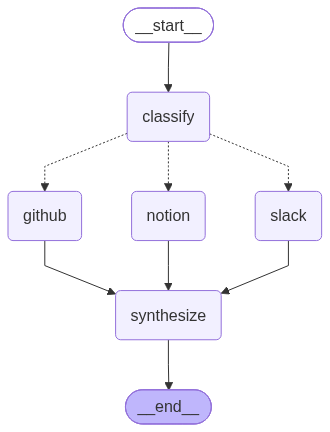

In [18]:
workflow = (
    StateGraph(RouterState)
    .add_node("classify", classify_query)
    .add_node("github", query_github)
    .add_node("notion", query_notion)
    .add_node("slack", query_slack)
    .add_node("synthesize", synthesize_results)

    .add_edge(START, "classify")
    .add_conditional_edges("classify", route_to_agents, ["github", "notion", "slack"])
    .add_edge("github", "synthesize")
    .add_edge("notion", "synthesize")
    .add_edge("slack", "synthesize")
    .add_edge("synthesize", END)
    .compile()   # 编译
)
workflow

In [ ]:
result = workflow.invoke({
    "query": "我该如何验证 API 请求？"
})

print("原始查询：", result["query"])
print("\n分类结果:")
for c in result["classification"]:
    print(f"  {c['source']}: {c['query']}")
print("\n" + "=" * 60 + "\n")
print("最终答案：")
print(result["final_answer"])